# Exercise 4: Short-Time Fourier Transform

This exercise develops understanding of the Short-Time Fourier Transform (STFT) and its applications in audio analysis. It has four parts:
1. Extract the main lobe of the spectrum of a window
2. Measure reconstruction noise using the STFT model
3. Compute band-wise energy envelopes of an audio signal
4. Compute an onset detection function

### Relevant concepts

**Main lobe of a window spectrum:** The width of the main lobe of a window's magnitude spectrum determines the frequency resolution of the analysis. Wider main lobes mean poorer frequency resolution but lower side lobes (better dynamic range). Importantly, changing the window length $M$ does **not** change the main-lobe width *in samples* — it only changes the frequency resolution in Hz. Zero-padding by a factor $P$ scales the main-lobe width by $P$ samples but not in normalized frequency.

**Fast Fourier Transform (FFT):** The FFT exploits the symmetry of the DFT matrix to reduce computation from $O(N^2)$ to $O(N \log N)$. It is most efficient when $N$ is a power of 2, which is the standard choice in audio processing.

**Energy of a signal:** The energy of a discrete-time signal $x[n]$ of length $N$ is:

$$E = \sum_{n=0}^{N-1} |x[n]|^2$$

**Energy in a frequency band:** Given a DFT spectrum $X[k]$ (in linear scale), the energy in the band spanning bins $k_1$ to $k_2$ is:

$$E = \sum_{k=k_1}^{k_2} |X[k]|^2$$

The `stftAnal()` function returns magnitudes in dB — convert to linear scale before summing energies. The result can then be expressed in dB as $E_{\mathrm{dB}} = 10\log_{10}(E)$.

**Signal-to-noise ratio (SNR):** SNR quantifies the amount of distortion introduced by analysis and synthesis. In the context of the STFT model:

$$\mathrm{SNR} = 10\log_{10}\!\left(\frac{E_{\mathrm{signal}}}{E_{\mathrm{noise}}}\right)$$

where $E_{\mathrm{noise}}$ is the energy of the difference between the original and reconstructed signal.

**Onset detection function (ODF):** An ODF assigns one value per audio frame and has high values at the onset of acoustic events. A simple energy-based ODF measures the increase in band energy between consecutive frames:

$$O(l) = E(l) - E(l-1), \quad l \geq 1$$

with initial condition $O(0) = 0$. To detect only onsets (not offsets), apply **half-wave rectification**:

$$\bar{O}(l) = \max(O(l),\; 0)$$


## Part 1 – Extracting the main lobe of the spectrum of a window

The function `extract_main_lobe()` should extract the main lobe of the magnitude spectrum of a window and return it in dB.

**Steps:**
1. Generate a window of type `window` and length `M` using `get_window()`.
2. Compute its `N`-point FFT with zero-phase windowing. Use `N = 8*M` (need not be a power of 2 for this part).
3. Compute the magnitude spectrum in dB: $m_W = 20\log_{10}(|W| + \varepsilon)$ where `eps = np.finfo(float).eps`.
4. Use `fftshift()` to centre the spectrum around DC.
5. Find the two local minima flanking the main lobe (the first minima on either side of the peak). Return the samples from the left minima to the right minima **inclusive**.

**Inputs:**
- `window` (str): window type — `'boxcar'`, `'hamming'`, or `'blackmanharris'`
- `M` (int): window length
- `N` (int): FFT size

**Output:** np.array containing the main-lobe samples in dB (including both boundary minima).

> Tip: scan outward from the peak index and stop as soon as the spectrum starts rising again to locate each minima.


In [2]:
import numpy as np
from scipy.signal import get_window
from scipy.fftpack import fft, fftshift
import matplotlib.pyplot as plt
eps = np.finfo(float).eps
from smstools.models import stft
from smstools.models import utilFunctions as UF

In [3]:
# E4 - 1.1: Complete function extract_main_lob()

def extract_main_lobe(window, M, N):
    """Extract the main lobe of the magnitude spectrum of a window, given a window type and its length.

    Args:
        window (str): Window type to be used (either rectangular ('boxcar'), 'hamming' or 'blackmanharris')
        M (int): length of the window to be used
        N (int): size of FFT

    Results:
        np.array: an array containing the main lobe of the magnitude spectrum of the window in decibels (dB).
    """

    # 1. Generate window
    w = get_window(window, M)

    # 2. Compute magnitude spectrum
    mx = fft(w, n=N)
    mx_db = 20 * np.log10(np.abs(mx) + np.finfo(float).eps)
    mx_db_centred = fftshift(mx_db)

    # 3. Find maximum (center of main lobe)
    max_idx = np.argmax(mx_db_centred)

    # 4. Search left until the spectrum starts rising
    left_idx = max_idx
    while left_idx > 0 and mx_db_centred[left_idx - 1] < mx_db_centred[left_idx]:
        left_idx -= 1

    # 5. Search right until the spectrum starts rising
    right_idx = max_idx
    while right_idx < N - 1 and mx_db_centred[right_idx + 1] < mx_db_centred[right_idx]:
        right_idx += 1

    # 6. Extract main lobe
    main_lobe = mx_db_centred[left_idx:right_idx + 1]

    return main_lobe



Test cases for `extract_main_lobe()`:

**Test case 1:** `window = 'blackmanharris'`, `M = 100`, `N = 800` → output has **65 samples**.

**Test case 2:** `window = 'boxcar'`, `M = 120`, `N = 960` → output has **17 samples**.

**Test case 3:** `window = 'hamming'`, `M = 256`, `N = 2048` → output has **33 samples**.

Plot the full magnitude spectrum of each window (x-axis in normalized samples or bins) and mark the two boundary minima of the main lobe. Compute the **normalized main-lobe width** by dividing the sample count by the zero-padding factor ($N/M$) and compare with the theoretical values from the lectures.


blackmanharris  M= 100 N=  800  samples= 65  zero-padding=8  normalized width=8.00 bins
boxcar          M= 120 N=  960  samples= 17  zero-padding=8  normalized width=2.00 bins
hamming         M= 256 N= 2048  samples= 33  zero-padding=8  normalized width=4.00 bins


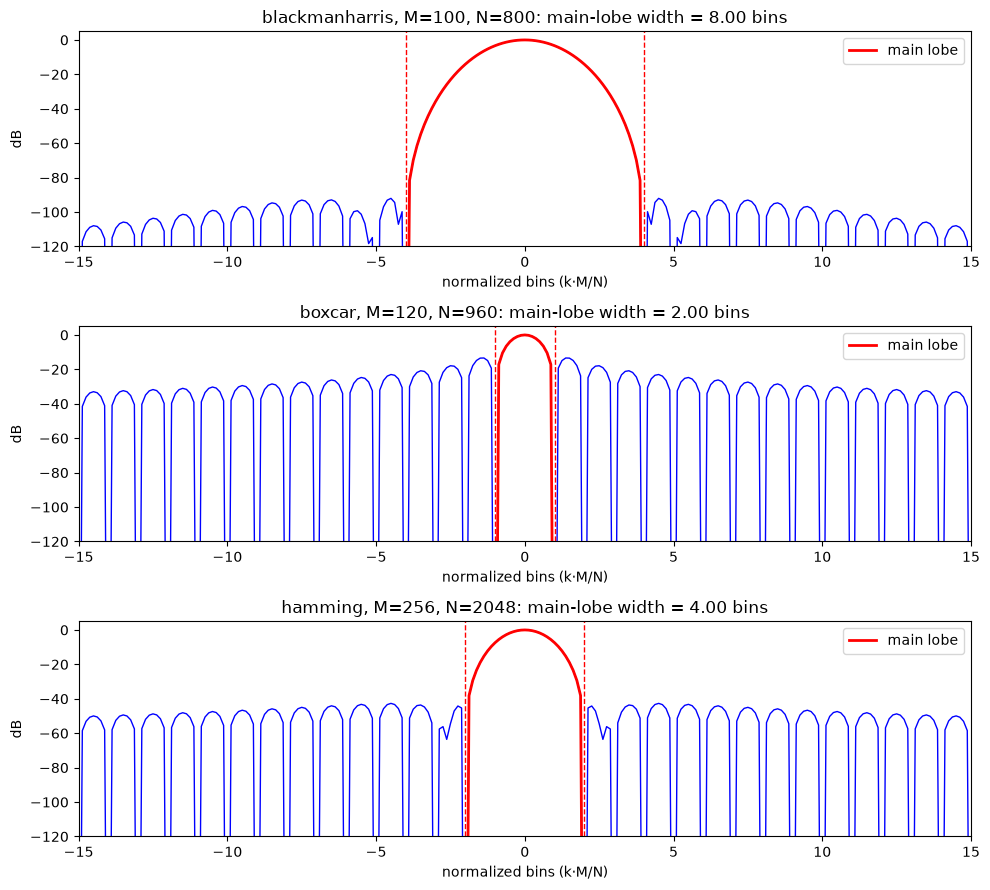

In [4]:
# E4 - 1.2: Call extract_main_lobe() for the 3 test cases, plot the magnitude spectrum of each window
#            with the main-lobe boundaries marked. Compute and report the normalized main-lobe width.

test_cases = [('blackmanharris', 100, 800), ('boxcar', 120, 960), ('hamming', 256, 2048)]

fig, axes = plt.subplots(len(test_cases), 1, figsize=(10, 9))

for ax, (window, M, N) in zip(axes, test_cases):
    main_lobe = extract_main_lobe(window, M, N)

    # Full centred magnitude spectrum (same computation as in extract_main_lobe)
    w = get_window(window, M)
    mx_db_centred = fftshift(20 * np.log10(np.abs(fft(w, n=N)) + eps))
    mx_db_centred -= mx_db_centred.max()            # normalize peak to 0 dB

    # Boundaries of the main lobe: it is symmetric around the peak
    max_idx = np.argmax(mx_db_centred)
    half = (len(main_lobe) - 1) // 2
    left_idx, right_idx = max_idx - half, max_idx + half

    # x-axis in normalized bins (bins of an N = M DFT), so zero-padding does not change the scale
    zp = N / M
    bins = (np.arange(N) - max_idx) / zp

    # Normalized main-lobe width: distance between the two minima divided by the zero-padding factor
    width = (len(main_lobe) - 1) / zp
    print(f"{window:15s} M={M:4d} N={N:5d}  samples={len(main_lobe):3d}  "
          f"zero-padding={zp:.0f}  normalized width={width:.2f} bins")

    ax.plot(bins, mx_db_centred, 'b', lw=1)
    ax.plot(bins[left_idx:right_idx + 1], mx_db_centred[left_idx:right_idx + 1], 'r', lw=2, label='main lobe')
    for b in (bins[left_idx], bins[right_idx]):    # minima are ~-300 dB, so mark them with vertical lines
        ax.axvline(b, color='r', ls='--', lw=1)
    ax.set_xlim(-15, 15)
    ax.set_ylim(-120, 5)
    ax.set_title(f"{window}, M={M}, N={N}: main-lobe width = {width:.2f} bins")
    ax.set_xlabel('normalized bins (k·M/N)')
    ax.set_ylabel('dB')
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

**E4 - 1.3: Conceptual questions (answer here)**

1. From your plots, report the normalized main-lobe width (in samples) for each of the three window types. How do they compare to the theoretical values (`boxcar` = 2, `hamming` = 4, `blackmanharris` = 8 bins in normalized frequency)?
2. The description says that changing `M` does not affect the main-lobe width in samples. Verify this: run `extract_main_lobe('hamming', M=128, N=1024)` and `extract_main_lobe('hamming', M=256, N=2048)`. Are the output lengths the same? Explain why.
3. What is the tradeoff between main-lobe width and side-lobe attenuation? Given this tradeoff, which window would you choose for analysing a signal with two closely spaced frequency components, and which for a signal where one component is much weaker than another?

   **Answer:** A window cannot have both a narrow main lobe and very low side lobes. Lowering the side lobes requires a smoother taper towards 0 at the edges (summing more cosine terms), and each extra cosine term widens the main lobe by 2 bins:

   | Window | Main-lobe width | Highest side lobe |
   |---|---|---|
   | boxcar | 2 bins | −13 dB |
   | hamming | 4 bins | −43 dB |
   | blackmanharris | 8 bins | −92 dB |

   - A **narrow main lobe** gives better **frequency resolution** (separating close frequencies): two components are resolved only if $\Delta f \ge B\, f_s/M$, i.e. $M \ge B\, f_s/\Delta f$.
   - **Low side lobes** give less **leakage** (a strong component does not mask a weak one).

   - **Two closely spaced components (similar amplitude):** a window with a narrow main lobe. `boxcar` gives the best resolution, but only if no strong components are nearby. In practice `hamming` is the better choice (4 bins with side lobes at −43 dB).
   - **One component much weaker than another:** `blackmanharris`. Its −92 dB side lobes do not hide the weak component, whereas with `boxcar` it would be buried under the −13 dB side lobes of the strong one. The price is a wider main lobe, so a longer window ($M \ge 8\, f_s/\Delta f$) is needed to keep the two lobes apart.

1. Already computed in the previous section. Are exctly the same compared with the theoretycal ones 

In [5]:
len(extract_main_lobe('hamming', M=128, N=1024))


33

In [6]:
extract_main_lobe('hamming', M=128, N=1024)

array([-310.77252318,   -1.34702184,    7.44419152,   13.33650824,
         17.86876991,   21.54773539,   24.61155649,   27.19402295,
         29.37875611,   31.22173494,   32.76215758,   34.02824844,
         35.04060189,   35.81421115,   36.35973986,   36.68432594,
         36.79207459,   36.68432594,   36.35973986,   35.81421115,
         35.04060189,   34.02824844,   32.76215758,   31.22173494,
         29.37875611,   27.19402295,   24.61155649,   21.54773539,
         17.86876991,   13.33650824,    7.44419152,   -1.34702184,
       -310.77252318])

In [7]:
len(extract_main_lobe('hamming', M=256, N=2048))

33

In [8]:
extract_main_lobe('hamming', M=256, N=2048)

array([-302.22701235,    4.66584113,   13.46067531,   19.35490503,
         23.88821244,   27.56775781,   30.63189891,   33.21453692,
         35.39935603,   37.24237174,   38.78280396,   40.04889024,
         41.06123297,   41.8348303 ,   42.38034882,   42.70492818,
         42.8126745 ,   42.70492818,   42.38034882,   41.8348303 ,
         41.06123297,   40.04889024,   38.78280396,   37.24237174,
         35.39935603,   33.21453692,   30.63189891,   27.56775781,
         23.88821244,   19.35490503,   13.46067531,    4.66584113,
       -302.22701235])

El lóbulo principal de una Hamming mide siempre 4 bins de una DFT con N = M. Es una propiedad de la forma de la ventana, no de su longitud.
Con zero-padding, cada uno de esos bins se reparte en N/M muestras. En los dos casos N/M = 1024/128 = 2048/256 = 8.
Por tanto, el lóbulo ocupa 4 × 8 = 32 muestras entre los dos mínimos, que son 33 muestras contando los dos extremos.
Lo que sí cambia es el ancho en Hz. Un bin vale fs/M, así que el lóbulo mide 4·fs/M:

Ancho del lóbulo (fs = 44100)
M = 128	4·44100/128 ≈ 1378 Hz
M = 256	4·44100/256 ≈ 689 Hz
Duplicar M deja igual el ancho del lóbulo en muestras (para el mismo factor de zero-padding), pero lo reduce a la mitad en frecuencia. Es decir, duplica la resolución en frecuencia, que es lo que dice el enunciado de la parte 1.





3. Para separar dos componentes de frecuencia cercanas usaria hamming si unicamente me preocupase eso, y una mas weaker que otro suponiendo no una cercania extrema usaria blackman harris porque no deja un leakage tan grande para el resto de frecuencias. leakage vs resolution es el tradeoff.

## Part 2 – Measuring reconstruction noise using the STFT model

The function `compute_snr()` should quantify the distortion introduced by STFT analysis followed by synthesis, using the signal-to-noise ratio (SNR) in dB.

**Steps:**
1. Load the audio file using `UF.wavread()`.
2. Run STFT analysis and synthesis via `stft.stftAnal()` and `stft.stftSynth()`.
3. Trim the output to the same length as the input (synthesis may be slightly longer).
4. Compute the noise signal as `noise = input_signal - output_signal`.
5. Calculate two SNR values:
   - **SNR1**: over the full signal length
   - **SNR2**: after discarding the first and last `M` samples (reduces boundary effects)

**Inputs:**
- `input_file` (str): path to a `.wav` file
- `window` (str): analysis window type
- `M` (int): window length (odd)
- `N` (int): FFT size (power of 2, $N > M$)
- `H` (int): hop size

**Output:** tuple `(SNR1, SNR2)` — both values in dB.


In [9]:
def compute_snr(input_file, window, M, N, H):
    """..."""
    ### your code here
    fs, x = UF.wavread(input_file)
    w = get_window(window, M)
    mX, pX = stft.stftAnal(x, w, N, H)
    y = stft.stftSynth(mX, pX, M, H)   # el factor H ya deshace la normalización
    y = y[:x.size]                      # recortar a la longitud de x

    noise = x - y

    ex     = np.sum(x**2)
    enoise = np.sum(noise**2)
    ex_sub     = np.sum(x[M:-M]**2)
    enoise_sub = np.sum(noise[M:-M]**2)

    snr1 = 10 * np.log10(ex / enoise)
    snr2 = 10 * np.log10(ex_sub / enoise_sub)
    return snr1, snr2

    


    

Test cases for `compute_snr()`:

**Test case 1:** `piano.wav`, `window = 'blackman'`, `M = 513`, `N = 2048`, `H = 128`
→ expected: `(SNR1 ≈ 67.6 dB, SNR2 ≈ 86.4 dB)`

**Test case 2:** `sax-phrase-short.wav`, `window = 'hamming'`, `M = 512`, `N = 1024`, `H = 64`
→ expected: `(SNR1 ≈ 89.5 dB, SNR2 ≈ 306.2 dB)`

**Test case 3:** `rain.wav`, `window = 'hann'`, `M = 1024`, `N = 2048`, `H = 128`
→ expected: `(SNR1 ≈ 74.6 dB, SNR2 ≈ 304.3 dB)`

> Note: SNR values may vary slightly across machines due to floating-point differences.


In [10]:
# E4 - 2.2: Call the function compute_snr() for the 3 test cases mentioned, explain the results

### Your code here
# E4 - 2.2: Call the function compute_snr() for the 3 test cases mentioned, explain the results

### Your code here
tests = [
    ('../sounds/piano.wav',            'blackman', 513, 2048, 128),
    ('../sounds/sax-phrase-short.wav', 'hamming',  512, 1024,  64),
    ('../sounds/rain.wav',             'hann',    1024, 2048, 128),
]

for f, window, M, N, H in tests:
    snr1, snr2 = compute_snr(f, window, M, N, H)
    print(f"{f.split('/')[-1]:22s} {window:9s} M={M:5d} H={H:4d} -> SNR1 = {snr1:6.1f} dB, SNR2 = {snr2:6.1f} dB")


piano.wav              blackman  M=  513 H= 128 -> SNR1 =   67.5 dB, SNR2 =   86.4 dB
sax-phrase-short.wav   hamming   M=  512 H=  64 -> SNR1 =   89.5 dB, SNR2 =  307.0 dB
rain.wav               hann      M= 1024 H= 128 -> SNR1 =   74.6 dB, SNR2 =  306.7 dB


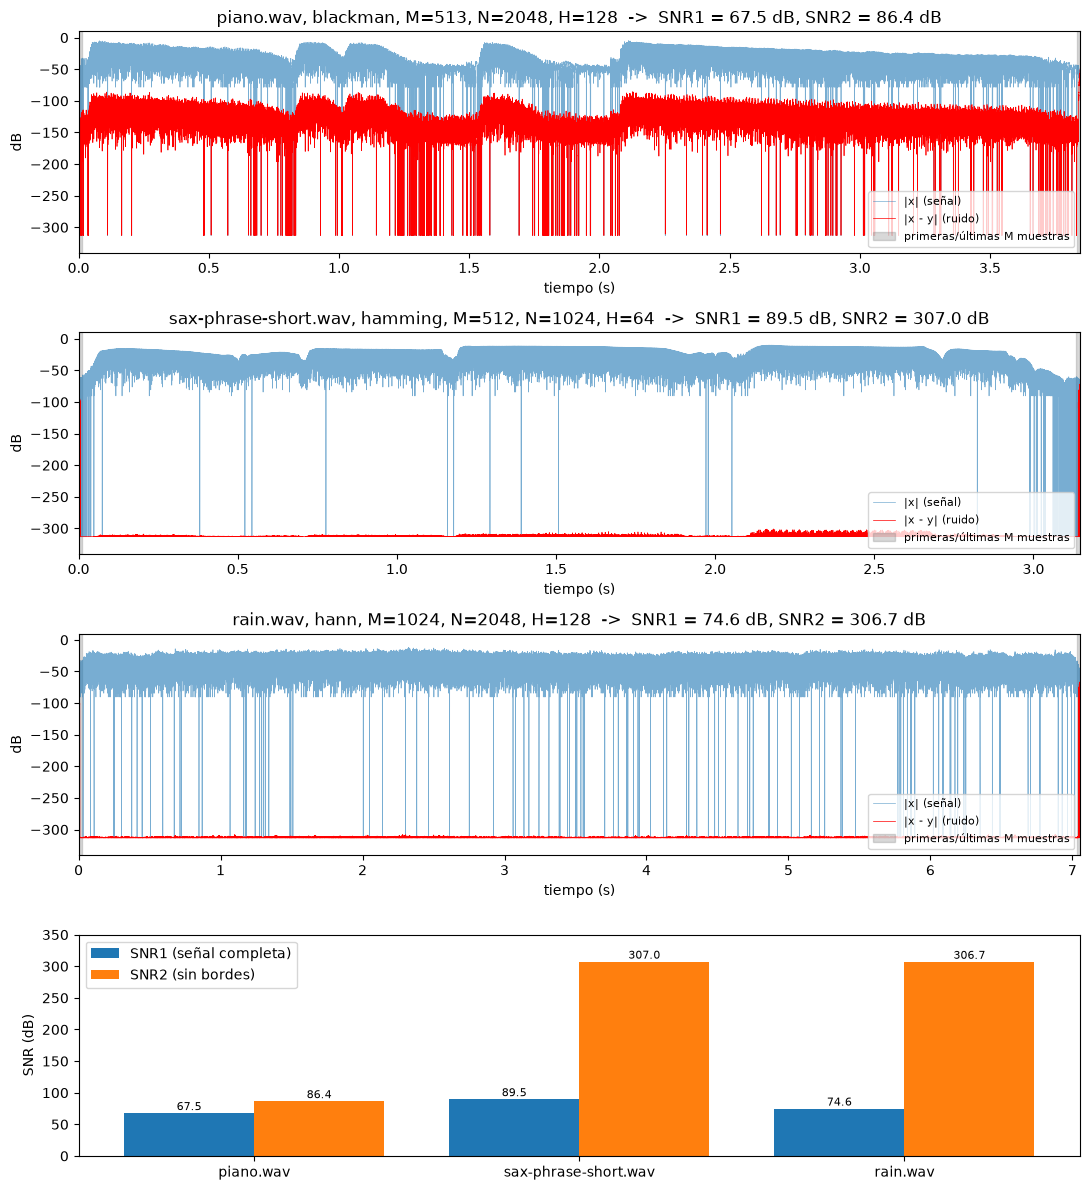

sonido                 ventana       M    H    M/H    SNR1    SNR2
piano.wav              blackman    513  128   4.01    67.5    86.4
sax-phrase-short.wav   hamming     512   64   8.00    89.5   307.0
rain.wav               hann       1024  128   8.00    74.6   306.7


In [11]:
# E4 - 2.2: Call the function compute_snr() for the 3 test cases mentioned, explain the results

### Your code here
tests = [
    ('../sounds/piano.wav',            'blackman', 513, 2048, 128),
    ('../sounds/sax-phrase-short.wav', 'hamming',  512, 1024,  64),
    ('../sounds/rain.wav',             'hann',    1024, 2048, 128),
]

results = []
fig, axes = plt.subplots(len(tests) + 1, 1, figsize=(11, 12))

for ax, (f, window, M, N, H) in zip(axes, tests):
    snr1, snr2 = compute_snr(f, window, M, N, H)
    results.append((f.split('/')[-1], window, M, H, snr1, snr2))

    # repetir el análisis/síntesis para tener el ruido muestra a muestra
    fs, x = UF.wavread(f)
    w = get_window(window, M)
    mX, pX = stft.stftAnal(x, w, N, H)
    y = stft.stftSynth(mX, pX, M, H)[:x.size]
    noise = x - y

    t = np.arange(x.size) / fs
    ax.plot(t, 20 * np.log10(np.abs(x) + eps), lw=0.5, alpha=0.6, label='|x| (señal)')
    ax.plot(t, 20 * np.log10(np.abs(noise) + eps), lw=0.5, color='r', label='|x - y| (ruido)')
    ax.axvspan(0, M / fs, color='gray', alpha=0.3, label='primeras/últimas M muestras')
    ax.axvspan((x.size - M) / fs, x.size / fs, color='gray', alpha=0.3)
    ax.set_xlim(0, x.size / fs)
    ax.set_ylim(-340, 10)
    ax.set_title(f"{f.split('/')[-1]}, {window}, M={M}, N={N}, H={H}  ->  "
                 f"SNR1 = {snr1:.1f} dB, SNR2 = {snr2:.1f} dB")
    ax.set_xlabel('tiempo (s)')
    ax.set_ylabel('dB')
    ax.legend(loc='lower right', fontsize=8)

# barras SNR1 vs SNR2
names = [r[0] for r in results]
pos = np.arange(len(results))
ax = axes[-1]
ax.bar(pos - 0.2, [r[4] for r in results], 0.4, label='SNR1 (señal completa)')
ax.bar(pos + 0.2, [r[5] for r in results], 0.4, label='SNR2 (sin bordes)')
for p, r in zip(pos, results):
    ax.text(p - 0.2, r[4] + 5, f'{r[4]:.1f}', ha='center', fontsize=8)
    ax.text(p + 0.2, r[5] + 5, f'{r[5]:.1f}', ha='center', fontsize=8)
ax.set_xticks(pos)
ax.set_xticklabels(names)
ax.set_ylabel('SNR (dB)')
ax.set_ylim(0, 350)
ax.legend()

plt.tight_layout()
plt.show()

print(f"{'sonido':22s} {'ventana':9s} {'M':>5s} {'H':>4s} {'M/H':>6s} {'SNR1':>7s} {'SNR2':>7s}")
for name, window, M, H, snr1, snr2 in results:
    print(f"{name:22s} {window:9s} {M:5d} {H:4d} {M/H:6.2f} {snr1:7.1f} {snr2:7.1f}")


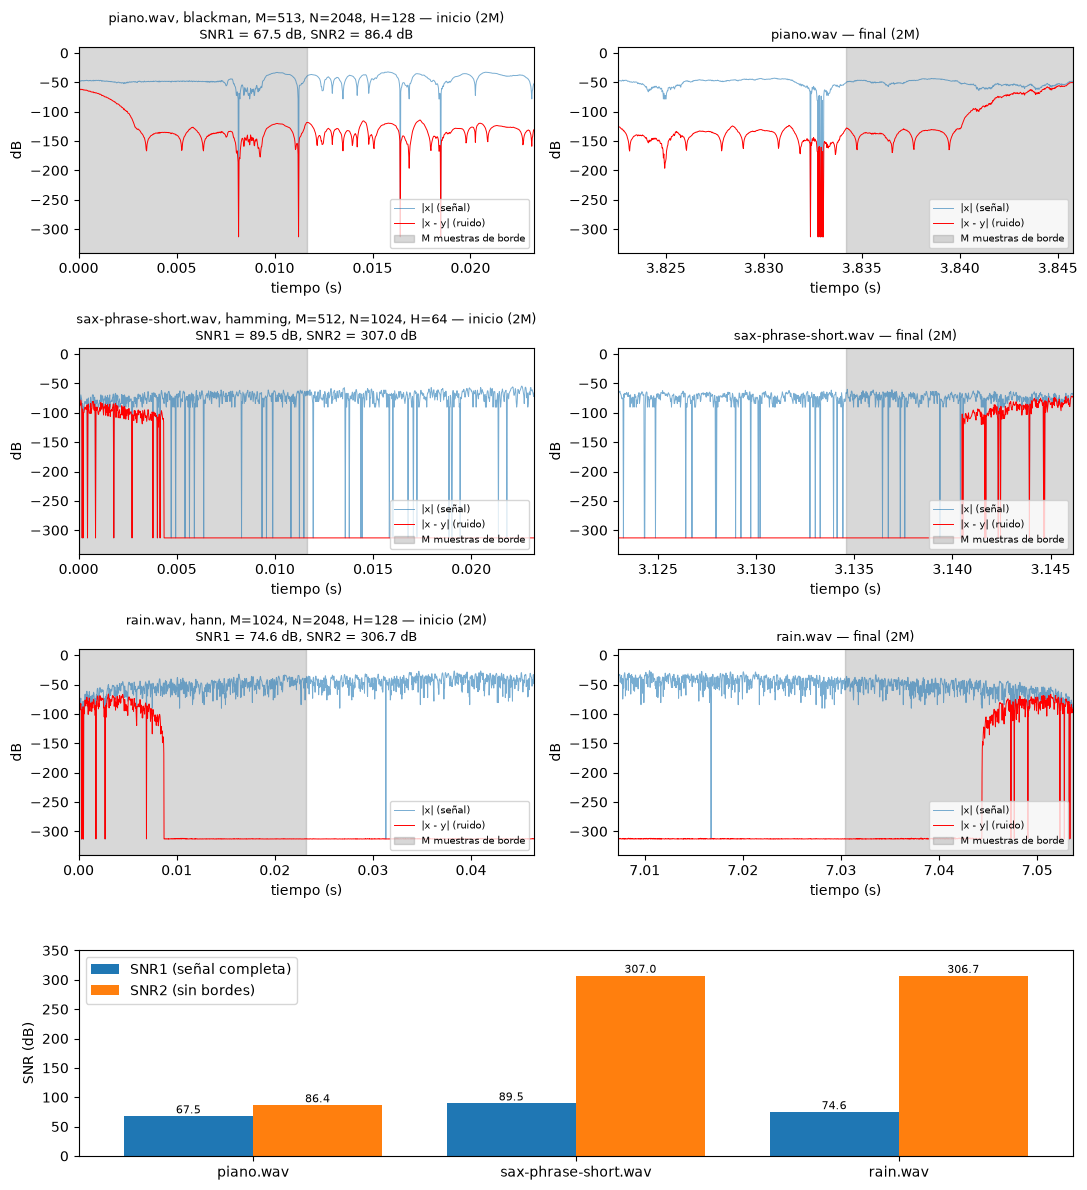

sonido                 ventana       M    H    M/H    SNR1    SNR2
piano.wav              blackman    513  128   4.01    67.5    86.4
sax-phrase-short.wav   hamming     512   64   8.00    89.5   307.0
rain.wav               hann       1024  128   8.00    74.6   306.7


In [12]:
# E4 - 2.2: Call the function compute_snr() for the 3 test cases mentioned, explain the results

### Your code here
tests = [
    ('../sounds/piano.wav',            'blackman', 513, 2048, 128),
    ('../sounds/sax-phrase-short.wav', 'hamming',  512, 1024,  64),
    ('../sounds/rain.wav',             'hann',    1024, 2048, 128),
]

results = []
mosaic = [[f'ini{i}', f'fin{i}'] for i in range(len(tests))] + [['bar', 'bar']]
fig, axd = plt.subplot_mosaic(mosaic, figsize=(11, 12))

for i, (f, window, M, N, H) in enumerate(tests):
    snr1, snr2 = compute_snr(f, window, M, N, H)
    results.append((f.split('/')[-1], window, M, H, snr1, snr2))

    # repetir el análisis/síntesis para tener el ruido muestra a muestra
    fs, x = UF.wavread(f)
    w = get_window(window, M)
    mX, pX = stft.stftAnal(x, w, N, H)
    y = stft.stftSynth(mX, pX, M, H)[:x.size]
    noise = x - y

    # solo las primeras y últimas 2M muestras, donde se concentra el error
    t = np.arange(x.size) / fs
    L = 2 * M
    tramos = [(axd[f'ini{i}'], slice(0, L),             (0, M),             'inicio'),
              (axd[f'fin{i}'], slice(x.size - L, x.size), (x.size - M, x.size), 'final')]
    for ax, sl, (a, b), lado in tramos:
        ax.plot(t[sl], 20 * np.log10(np.abs(x[sl]) + eps), lw=0.7, alpha=0.6, label='|x| (señal)')
        ax.plot(t[sl], 20 * np.log10(np.abs(noise[sl]) + eps), lw=0.7, color='r', label='|x - y| (ruido)')
        ax.axvspan(a / fs, b / fs, color='gray', alpha=0.3, label='M muestras de borde')
        ax.set_xlim(t[sl][0], t[sl][-1])
        ax.set_ylim(-340, 10)
        ax.set_xlabel('tiempo (s)')
        ax.set_ylabel('dB')
        ax.legend(loc='lower right', fontsize=7)
    axd[f'ini{i}'].set_title(f"{f.split('/')[-1]}, {window}, M={M}, N={N}, H={H} — inicio (2M)\n"
                             f"SNR1 = {snr1:.1f} dB, SNR2 = {snr2:.1f} dB", fontsize=9)
    axd[f'fin{i}'].set_title(f"{f.split('/')[-1]} — final (2M)", fontsize=9)

# barras SNR1 vs SNR2
names = [r[0] for r in results]
pos = np.arange(len(results))
ax = axd['bar']
ax.bar(pos - 0.2, [r[4] for r in results], 0.4, label='SNR1 (señal completa)')
ax.bar(pos + 0.2, [r[5] for r in results], 0.4, label='SNR2 (sin bordes)')
for p, r in zip(pos, results):
    ax.text(p - 0.2, r[4] + 5, f'{r[4]:.1f}', ha='center', fontsize=8)
    ax.text(p + 0.2, r[5] + 5, f'{r[5]:.1f}', ha='center', fontsize=8)
ax.set_xticks(pos)
ax.set_xticklabels(names)
ax.set_ylabel('SNR (dB)')
ax.set_ylim(0, 350)
ax.legend()

plt.tight_layout()
plt.show()

print(f"{'sonido':22s} {'ventana':9s} {'M':>5s} {'H':>4s} {'M/H':>6s} {'SNR1':>7s} {'SNR2':>7s}")
for name, window, M, H, snr1, snr2 in results:
    print(f"{name:22s} {window:9s} {M:5d} {H:4d} {M/H:6.2f} {snr1:7.1f} {snr2:7.1f}")


**E4 - 2.3: Conceptual questions (answer here)**

1. For each test case, SNR2 is significantly higher than SNR1. What do the first and last `M` samples represent in the STFT reconstruction, and why are they noisier than the interior?
2. Compare SNR1 values across the three test cases (piano, sax, rain). The values differ substantially. What properties of the signal or the analysis parameters could explain these differences?
3. If you increase the hop size `H` while keeping `M` and `N` fixed, would you expect the SNR to increase or decrease? Why? Verify with one example.


1. Zona del overlap-add esta incompleto, primer frame esta centrado en la muestra 0, cerca del principio faltarian los frames que estarian centrados en -H. , seria como un fade in al principio y fade out al final. 
2. Casi todo el ruido de reconstrucción está en los bordes, es decir, en las primeras y últimas M muestras. Ahí se solapan menos ventanas, así que el overlap-add no llega a ganancia 1 y se pierde parte de la señal.

Por eso el SNR1 depende sobre todo de cuánta señal hay en los bordes en comparación con la energía total:

Saxo (89.5 dB): empieza y acaba casi en silencio. En los bordes hay poco que perder, así que tiene el SNR1 más alto.
Lluvia (74.6 dB): tiene ruido constante en los extremos, pero el archivo es largo (7 s) y eso diluye el error.
Piano (67.5 dB): tiene sonido en los extremos. Además, la combinación Blackman 513 con H = 128 no cumple COLA exactamente y deja un pequeño error también en el interior, así que es el peor.
M/H tiene que ser un numer entero, la suma de las ventanas da un rizado periodico. 



**Demostración: rizado periódico del overlap-add (por qué M = 513 con H = 128 deja ruido en el interior)**

`stftAnal` + `stftSynth` sin modificar el espectro equivale a multiplicar la señal por una ganancia: $y[n] = g[n]\,x[n]$, con

$$g[n] = \frac{H}{\sum_m w[m]} \sum_k w[n - kH]$$

- La suma de ventanas desplazadas **siempre es periódica con periodo $H$**.
- Si $M/H$ es entero (condición COLA), esa suma es constante: $g[n] = 1$ y la reconstrucción es perfecta (SNR2 ≈ 300 dB, precisión numérica).
- Con $M = 513 = 4H + 1$ cada ventana "sobra" una muestra: $g[n]$ oscila un poco cada $H$ muestras (**rizado periódico**) y el ruido es $x - y = (1 - g)\,x$.

**Por qué depende de la ventana:** lo que se suma de más está en el extremo de la ventana.
- Hamming vale 0.08 en el borde, así que aparece un pico de ≈ 0.08·H/Σw ≈ 3.7·10⁻² cada H muestras.
- Hann y Blackman valen 0 en el borde: el pico desaparece y solo queda un arco suave, menor en Blackman, que se acerca a cero de forma más plana.

Por tanto, Blackman es la ventana que **menos** sufre con M = 513. El SNR2 de 86 dB del piano se debe a M = 513, no a Blackman: con Hann serían 74 dB y con Hamming 50 dB. Además, en los bordes del archivo Blackman tiene la ganancia más cercana a 1 (g[0] ≈ 0.80 frente a 0.75).

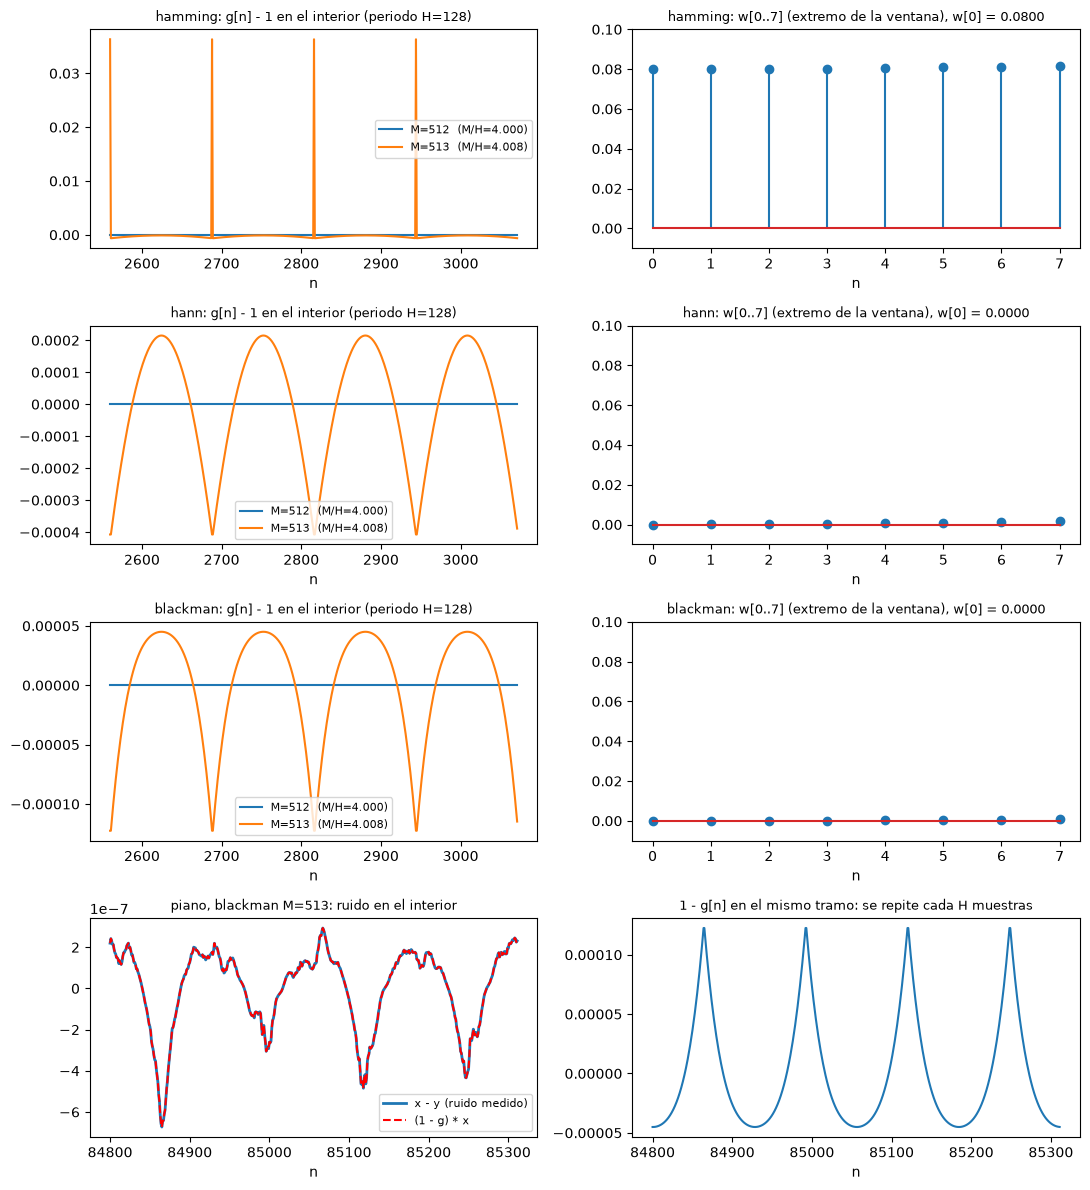

ventana      M    w[0]  rizado g (pico-pico)  g[0] borde    SNR1    SNR2
hamming    513  0.0800               3.7e-02       0.748    49.8    49.8
hamming    512  0.0800               7.4e-15       0.750    73.6   308.7
hann       513  0.0000               6.2e-04       0.748    66.7    74.4
hann       512  0.0000               7.3e-15       0.750    74.2   310.1
blackman   513  0.0000               1.7e-04       0.795    67.5    86.4
blackman   512  0.0000               7.5e-15       0.798    77.0   310.9


In [13]:
# Demostración: rizado periódico del overlap-add
# Si analizamos y sintetizamos una señal constante (todo unos), la salida es
# directamente la ganancia del overlap-add g[n]. Para cualquier señal: y = g * x
N, H = 2048, 128
ventanas = ['hamming', 'hann', 'blackman']
fs, x = UF.wavread('../sounds/piano.wav')

def ganancia_ola(window, M, longitud):
    w = get_window(window, M)
    mX, pX = stft.stftAnal(np.ones(longitud), w, N, H)
    return stft.stftSynth(mX, pX, M, H)[:longitud]

n = np.arange(20 * H, 24 * H)    # 4 periodos de H en el interior
fig, axes = plt.subplots(len(ventanas) + 1, 2, figsize=(11, 12))

for row, window in zip(axes, ventanas):
    # izquierda: ganancia g[n] - 1 en el interior, M = 512 vs M = 513
    for M in (512, 513):
        g = ganancia_ola(window, M, x.size)
        row[0].plot(n, g[n] - 1, label=f'M={M}  (M/H={M/H:.3f})')
    row[0].set_title(f'{window}: g[n] - 1 en el interior (periodo H={H})', fontsize=9)
    row[0].set_xlabel('n')
    row[0].legend(fontsize=8)

    # derecha: valor de la ventana en sus primeras muestras (lo que "sobra" con M = 4H + 1)
    w = get_window(window, 513)
    row[1].stem(np.arange(8), w[:8])
    row[1].set_ylim(-0.01, 0.1)
    row[1].set_title(f'{window}: w[0..7] (extremo de la ventana), w[0] = {abs(w[0]):.4f}', fontsize=9)
    row[1].set_xlabel('n')

# abajo: en el piano (blackman, M=513) el ruido del interior es exactamente (1 - g) * x
M = 513
w = get_window('blackman', M)
mX, pX = stft.stftAnal(x, w, N, H)
y = stft.stftSynth(mX, pX, M, H)[:x.size]
noise = x - y
g = ganancia_ola('blackman', M, x.size)
seg = np.arange(x.size // 2, x.size // 2 + 4 * H)
ax = axes[-1, 0]
ax.plot(seg, noise[seg], lw=2, label='x - y (ruido medido)')
ax.plot(seg, (1 - g[seg]) * x[seg], 'r--', label='(1 - g) * x')
ax.set_title('piano, blackman M=513: ruido en el interior', fontsize=9)
ax.set_xlabel('n')
ax.legend(fontsize=8)
ax = axes[-1, 1]
ax.plot(seg, 1 - g[seg])
ax.set_title('1 - g[n] en el mismo tramo: se repite cada H muestras', fontsize=9)
ax.set_xlabel('n')

plt.tight_layout()
plt.show()

print(f"{'ventana':9s} {'M':>4s} {'w[0]':>7s} {'rizado g (pico-pico)':>21s} {'g[0] borde':>11s} {'SNR1':>7s} {'SNR2':>7s}")
for window in ventanas:
    for M in (513, 512):
        g = ganancia_ola(window, M, x.size)
        interior = g[2 * M:-2 * M]
        snr1, snr2 = compute_snr('../sounds/piano.wav', window, M, N, H)
        print(f"{window:9s} {M:4d} {abs(get_window(window, M)[0]):7.4f} {interior.max() - interior.min():21.1e} "
              f"{g[0]:11.3f} {snr1:7.1f} {snr2:7.1f}")

Respuesta corta para la pregunta 3: al aumentar H, el SNR se mantiene alto mientras el par ventana/hop siga cumpliendo COLA (M/H entero y solape suficiente: ≥ 2 para Hann/Hamming, ≥ 3 para Blackman). Si deja de cumplirse, aparece rizado en el interior y el SNR baja, cada vez más a medida que crece H. Ejemplo: Blackman con M = 512 da SNR2 ≈ 311 dB con H = 128, pero solo 17 dB con H = 256.



## Part 3 – Computing band-wise energy envelopes

The function `compute_eng_env()` should compute energy envelopes for two frequency bands of an audio signal using the STFT.

**Frequency bands:**
- **Low band:** $0 < f < 3000$ Hz (excluding boundaries)
- **High band:** $3000 < f < 10000$ Hz (excluding boundaries)

**Steps:**
1. Load the audio file and run `stftAnal()` to get the magnitude spectra in dB for all frames.
2. Convert magnitude spectra from dB back to linear scale: $|X| = 10^{m_X/20}$.
3. For each frame, use `np.where()` to find bin indices within each band. The bin frequency is $f_k = k \cdot f_s / N$.
4. Compute per-frame band energy as the sum of squared linear magnitudes across the band's bins.
5. Convert each energy value to dB: $E_{\mathrm{dB}} = 10\log_{10}(E)$.

**Inputs:**
- `input_file` (str): path to a mono `.wav` file (44100 Hz)
- `window` (str): analysis window type
- `M` (int): window length (odd, power-of-2 convenient)
- `N` (int): FFT size (power of 2, $N > M$)
- `H` (int): hop size

**Output:** 2D np.array with shape `(num_frames, 2)` — column 0 is the low-band envelope, column 1 is the high-band envelope, both in dB.


In [14]:
# E4 - 3.1: Complete function compute_eng_env()

def compute_eng_env(input_file, window, M, N, H):
    """Compute band-wise energy envelopes of a given audio signal using the STFT.

    Args:
        input_file (string): input sound file (monophonic with sampling rate of 44100)
        window (string): analysis window type (choice of rectangular, triangular, hanning,
                hamming, blackman, blackmanharris)
        M (integer): analysis window size (odd positive integer)
        N (integer): FFT size (power of 2, such that N > M)
        H (integer): hop size for the stft computation

    Result:
        np.array: magnitude spectra of sound (2D array)
        np.array: 2D numpy array with energy envelope of band 0 < f < 3000 Hz (in dB) in first column, [:,0]
        np.array: energy envelope of band 3000 < f < 10000 Hz (in dB) in second column [:,1]
    """

    ### your code here
    fs, x = UF.wavread(input_file)
    w = get_window(window, M)
    mX, pX = stft.stftAnal(x, w, N, H)

    mx_linear = 10**(mX/20)                      # dB -> magnitud lineal
    freqs = np.arange(mX.shape[1]) * fs / N      # Hz de cada bin

    band_low  = (freqs > 0)    & (freqs < 3000)   # 0 < f < 3000 (sin DC)
    band_high = (freqs > 3000) & (freqs < 10000)  # 3000 < f < 10000

    # energía = suma de |X|^2 en la banda, por frame, en dB
    eng_low  = 10*np.log10(np.sum(mx_linear[:, band_low]**2,  axis=1))
    eng_high = 10*np.log10(np.sum(mx_linear[:, band_high]**2, axis=1))

    eng_env = np.column_stack((eng_low, eng_high))
    return mX, eng_env

    
    

Test cases for `compute_eng_env()`:

**Test case 1:** `piano.wav`, `window = 'blackman'`, `M = 513`, `N = 1024`, `H = 128`
→ low band: bins 1–69 (69 bins); high band: bins 70–232 (163 bins)

**Test case 2:** `piano.wav`, `window = 'blackman'`, `M = 2047`, `N = 4096`, `H = 128`
→ low band: bins 1–278 (278 bins); high band: bins 279–928 (650 bins)

**Test case 3:** `sax-phrase-short.wav`, `window = 'hamming'`, `M = 513`, `N = 2048`, `H = 256`
→ low band: bins 1–139 (139 bins); high band: bins 140–464 (325 bins)

Plot both energy envelopes together with the signal's spectrogram (use `plt.pcolormesh` or reuse the code from `lectures/4-STFT/plots-code/spectrogram.py`). Use the same time-axis range for both. You should see sharp attacks and decays for the piano notes in test case 1 — compare with test case 2 (larger window) to observe the effect of window length on temporal resolution.


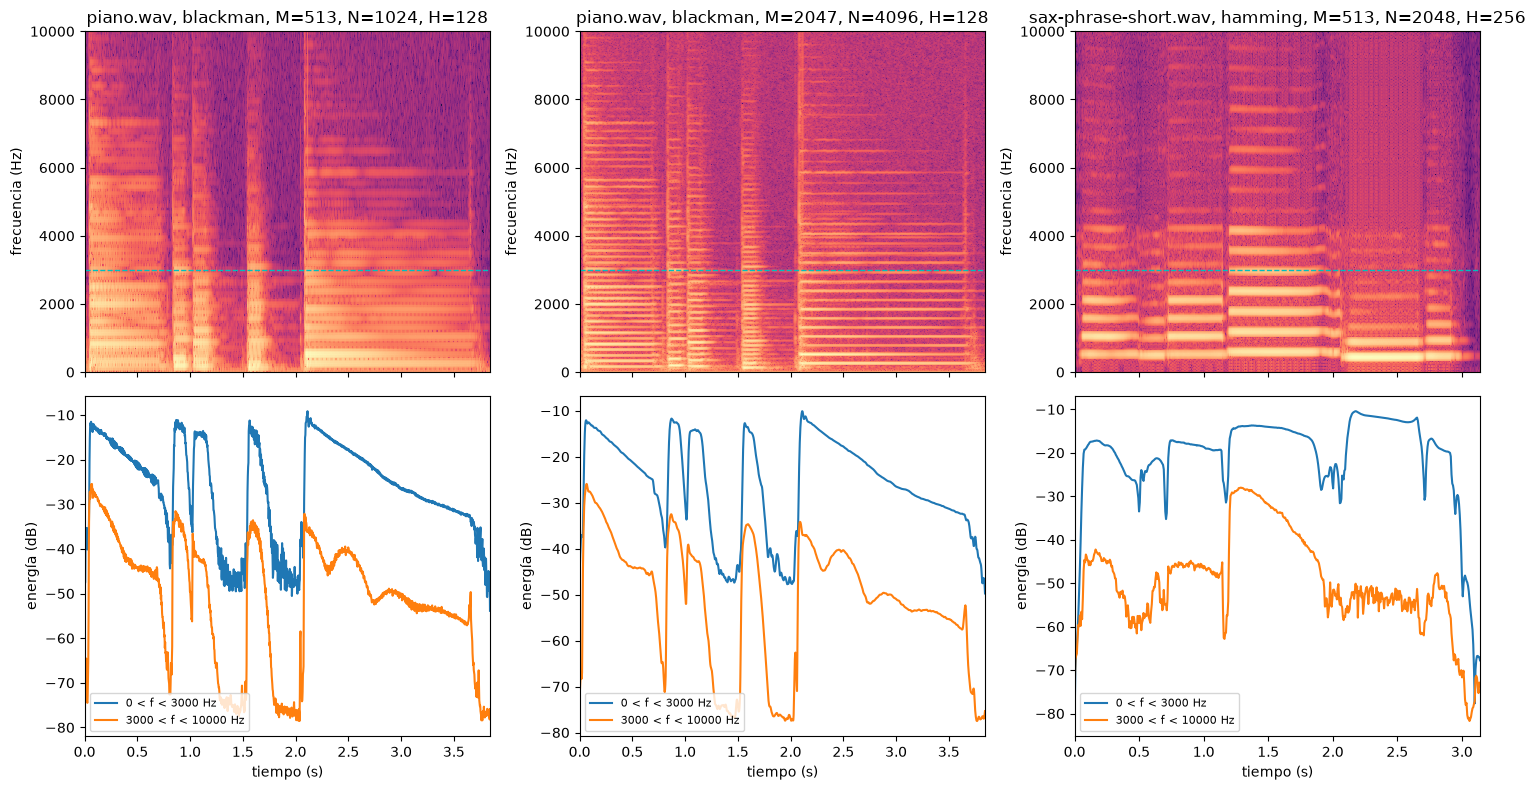

In [15]:
# E4 - 3.2: Call compute_eng_env() for the 3 test cases and plot both energy envelopes
#            together with the spectrogram. Use the same time axis for all subplots.

### Your code here
tests = [
    ('../sounds/piano.wav',            'blackman',  513, 1024, 128),
    ('../sounds/piano.wav',            'blackman', 2047, 4096, 128),
    ('../sounds/sax-phrase-short.wav', 'hamming',   513, 2048, 256),
]

fig, axes = plt.subplots(2, len(tests), figsize=(15, 8), sharex='col')

for j, (f, window, M, N, H) in enumerate(tests):
    mX, eng_env = compute_eng_env(f, window, M, N, H)
    fs = 44100
    n_frames, n_bins = mX.shape
    t = np.arange(n_frames) * H / fs          # tiempo de cada frame
    freqs = np.arange(n_bins) * fs / N        # Hz de cada bin

    # espectrograma, con las fronteras de las bandas marcadas
    ax = axes[0, j]
    ax.pcolormesh(t, freqs, mX.T, shading='auto', cmap='magma')
    ax.axhline(3000, color='c', ls='--', lw=1)
    ax.set_ylim(0, 10000)
    ax.set_title(f"{f.split('/')[-1]}, {window}, M={M}, N={N}, H={H}")
    ax.set_ylabel('frecuencia (Hz)')

    # envolventes de energía
    ax = axes[1, j]
    ax.plot(t, eng_env[:, 0], label='0 < f < 3000 Hz')
    ax.plot(t, eng_env[:, 1], label='3000 < f < 10000 Hz')
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel('tiempo (s)')
    ax.set_ylabel('energía (dB)')
    ax.legend(loc='lower left', fontsize=8)

plt.tight_layout()
plt.show()



**E4 - 3.3: Conceptual questions (answer here)**

1. From your spectrogram plot for test case 1 (`piano.wav`, `M=513`), visually identify a piano note onset and describe how the low-band and high-band envelopes behave at that moment. Which band reacts more sharply?
2. Compare envelopes from test case 1 (`M=513`) and test case 2 (`M=2047`) for the same file. How does increasing the window size affect the temporal sharpness of the note attacks in the envelope? Explain the underlying tradeoff.
3. Why is the DC bin (bin 0) excluded from the energy calculation? What kind of signal component does it represent, and what would happen to the energy values if you included it?


1. se identifica con una linea vertical estrecha junto antes de que la nota perdure. Las low band frequency reaccionan algo mas fuerte pero no lo destacarai especialmente. La high band reacciona mas sharply (grafica de abajo)
2. Noto mas estrecho el onset cuando M es mas pequeño lo que da una menor desviacion en saber exactamente cuando se hace el ataque. Es el famoso problema de la relacion entre resolucion temporal vs frecuencial. Podemos tener mejores resoluciones en la frecuencia pero a medida que tambien aumentamos M perdemos precision en el eje temporal.
3. El bin 0 representa la componente DC (0 Hz), el valor medio de la señal en el frame. No aporta información musical. Si la grabación tiene un offset de DC, incluirlo añadiría energía constante a la banda baja, subiendo el suelo de la envolvente y reduciendo el contraste de los onsets.

## Part 4 – Computing an onset detection function

The function `compute_odf()` should compute a half-wave-rectified energy-based ODF for two frequency bands, using the same low/high band definitions as Part 3.

**Steps:**
1. Compute the band-wise energy envelopes (in dB) exactly as in Part 3.
2. Compute the frame-to-frame energy difference: $O(l) = E(l) - E(l-1)$ for $l \geq 1$, with $O(0) = 0$.
3. Apply half-wave rectification: set all negative values to 0.

**Inputs:**
- `input_file` (str): path to a mono `.wav` file (44100 Hz)
- `window` (str): analysis window type
- `M` (int): window length (odd)
- `N` (int): FFT size (power of 2, $N > M$)
- `H` (int): hop size

**Output:** 2D np.array with shape `(num_frames, 2)` — column 0 is the ODF for the low band, column 1 for the high band.


In [16]:
# E4 4.1: Complete function compute_odf()

def compute_odf(input_file, window, M, N, H):
    """Compute a simple onset detection function (ODF) using the STFT.

    Args:
        input_file (str): input sound file (monophonic with sampling rate of 44100)
        window (str): analysis window type (rectangular, triangular, hanning, hamming, blackman, or blackmanharris)
        M (int): analysis window size (odd integer value)
        N (int): fft size (power of two, bigger or equal than than M)
        H (int): hop size for the STFT computation

    Result:
            np.array: magnitude spectra of sound (2D array)
            np.array: D numpy array with ODF computed in band 0 < f < 3000 Hz (in dB) in first column, [:,0]
            np.array: ODF computed of band 3000 < f < 10000 Hz (in dB) in second column [:,1]
    """

    mX, eng_env = compute_eng_env(input_file, window, M, N, H)

    odf = np.zeros_like(eng_env)
    odf[1:] = np.diff(eng_env, axis=0)
    odf[odf < 0] = 0

    return mX, odf


Test cases for `compute_odf()` (same parameters as Part 3):

**Test case 1:** `piano.wav`, `window = 'blackman'`, `M = 513`, `N = 1024`, `H = 128`

**Test case 2:** `piano.wav`, `window = 'blackman'`, `M = 2047`, `N = 4096`, `H = 128`

**Test case 3:** `sax-phrase-short.wav`, `window = 'hamming'`, `M = 513`, `N = 2048`, `H = 256`

Plot each ODF together with the spectrogram of the corresponding signal (same time axis). For test case 1, you should see **5 clear peaks above 10 dB** in the high-band ODF, corresponding to the onsets of the piano notes.


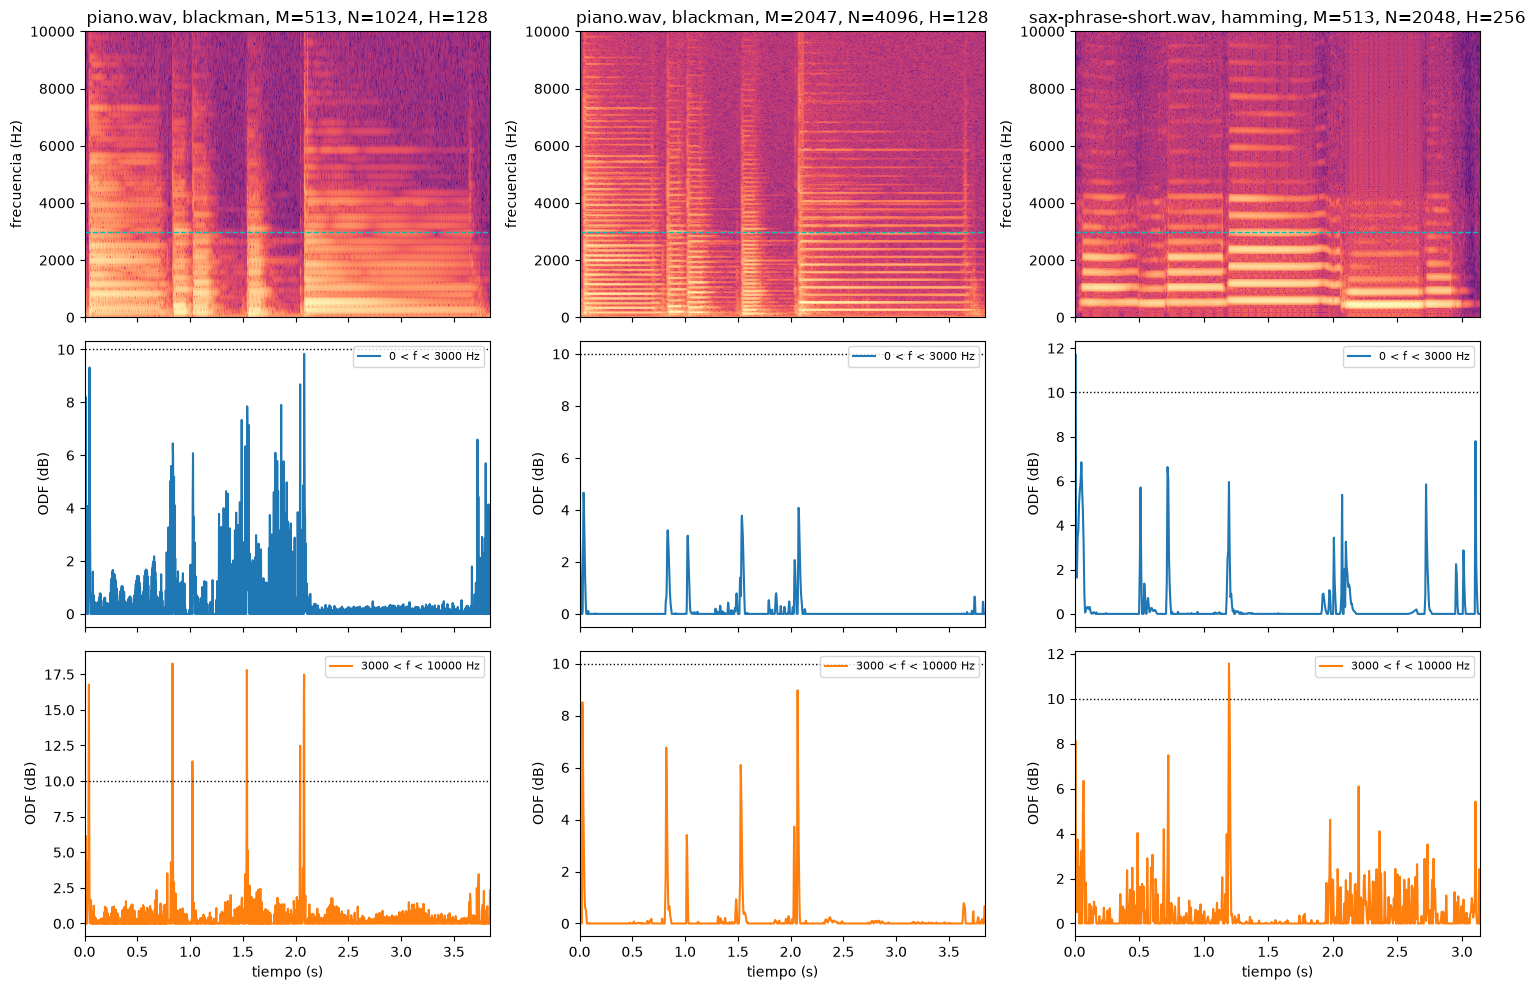

In [17]:
# E4 - 4.2: Call compute_odf() for the 3 test cases and plot the ODF functions together with
#            the spectrogram of the signal. Use the same time axis for both.

### Your code here
tests = [
    ('../sounds/piano.wav',            'blackman',  513, 1024, 128),
    ('../sounds/piano.wav',            'blackman', 2047, 4096, 128),
    ('../sounds/sax-phrase-short.wav', 'hamming',   513, 2048, 256),
]

fig, axes = plt.subplots(3, len(tests), figsize=(15, 10), sharex='col')

for j, (f, window, M, N, H) in enumerate(tests):
    mX, odf = compute_odf(f, window, M, N, H)
    fs = 44100
    n_frames, n_bins = mX.shape
    t = np.arange(n_frames) * H / fs          # tiempo de cada frame
    freqs = np.arange(n_bins) * fs / N        # Hz de cada bin

    # espectrograma
    ax = axes[0, j]
    ax.pcolormesh(t, freqs, mX.T, shading='auto', cmap='magma')
    ax.axhline(3000, color='c', ls='--', lw=1)
    ax.set_ylim(0, 10000)
    ax.set_title(f"{f.split('/')[-1]}, {window}, M={M}, N={N}, H={H}")
    ax.set_ylabel('frecuencia (Hz)')

    # ODF de cada banda, con el umbral de 10 dB
    for i, (label, color) in enumerate([('0 < f < 3000 Hz', 'C0'), ('3000 < f < 10000 Hz', 'C1')]):
        ax = axes[1 + i, j]
        ax.plot(t, odf[:, i], color=color, label=label)
        ax.axhline(10, color='k', ls=':', lw=1)
        ax.set_xlim(t[0], t[-1])
        ax.set_ylabel('ODF (dB)')
        ax.legend(loc='upper right', fontsize=8)
    axes[2, j].set_xlabel('tiempo (s)')

plt.tight_layout()
plt.show()



**E4 - 4.3: Conceptual questions (answer here)**

1. For test case 1 (`piano.wav`, `M=513`), count the peaks above 10 dB in the high-band ODF. Do they correspond to audible note onsets? Compare the peak locations in the low-band vs. high-band ODFs. Which band is more reliable for detecting piano note onsets, and why?
2. Compare the ODFs from test case 1 (`M=513`) and test case 2 (`M=2047`). How does window size affect the sharpness and height of the ODF peaks? Which would be easier to threshold for onset detection?
3. What is the effect of half-wave rectification on the ODF? Sketch (or plot) the ODF before and after rectification for one test case. What information is discarded, and why is it not needed for onset detection?
4. Could a single fixed dB threshold reliably detect onsets in all three test cases? Examine the ODF values across cases. If not, what alternative strategy would you propose?


1. High band es mas reliable para detectar onsets. Picos mas sharp y con menos leakage en comparacion con los de low band que mantiene multiplos picos alrededor.
En la banda alta hay 5 picos por encima de 10 dB (≈0.04, 0.83, 1.02, 1.54 y 2.05 s), que coinciden con los onsets audibles de las notas. En la banda baja los picos aparecen en los mismos instantes, pero son más bajos (ninguno supera 10 dB) y van acompañados de picos secundarios. La banda alta es más fiable porque el golpe del martillo es un transitorio de banda ancha que mete energía en altas frecuencias justo en el ataque, mientras que entre notas esa banda está casi en silencio, así que el salto relativo es grande. En la banda baja las notas anteriores siguen sonando (sustain, pedal) y los parciales graves fluctúan, de modo que el incremento relativo es menor y hay más picos espurios.


2. Con M=2047 (≈46 ms) los picos de la ODF son más anchos y mucho más bajos (máx ≈9 dB frente a ≈18 dB con M=513, ≈11.6 ms). Como cada frame promedia 46 ms y el hop sigue siendo 128 muestras, el ataque aparece de forma gradual a lo largo de unos 16 frames consecutivos, y la subida de energía se reparte en muchas diferencias pequeñas en lugar de una grande (temporal smearing). A cambio, la ODF es más suave y tiene menos ruido. Es el compromiso entre resolución temporal y frecuencial. Para detección de onsets interesa la resolución temporal: la ODF con M=513 es mucho más fácil de umbralizar porque sus picos destacan claramente sobre el resto.

3. La rectificación de media onda pone a 0 los valores negativos de la ODF, que corresponden a los frames donde la energía disminuye. En la gráfica sin rectificar la ODF oscila alrededor de 0: picos positivos en los ataques y valores negativos durante el decay y en los offsets de las notas (caídas bruscas cuando una nota se corta). Tras rectificar solo quedan los picos positivos. Se descarta la información de los decrementos de energía (decay y final de las notas). No hace falta porque un onset se define como un aumento repentino de energía. Además, eliminar la parte negativa evita confundir caídas fuertes con eventos y reduce a la mitad las fluctuaciones de ruido, así que la función queda más limpia para aplicar un umbral.
4. Obviamente no, podria hacerse una clusterizacion en 2 grupos de la energuia con un algoritmo no supervisado tipo kmeans, aunque lo mejor es usar un umbral adaptativo, como la mediana movil de la odf, quedarse solo maximos locales y exigir distancia minima entre onsets

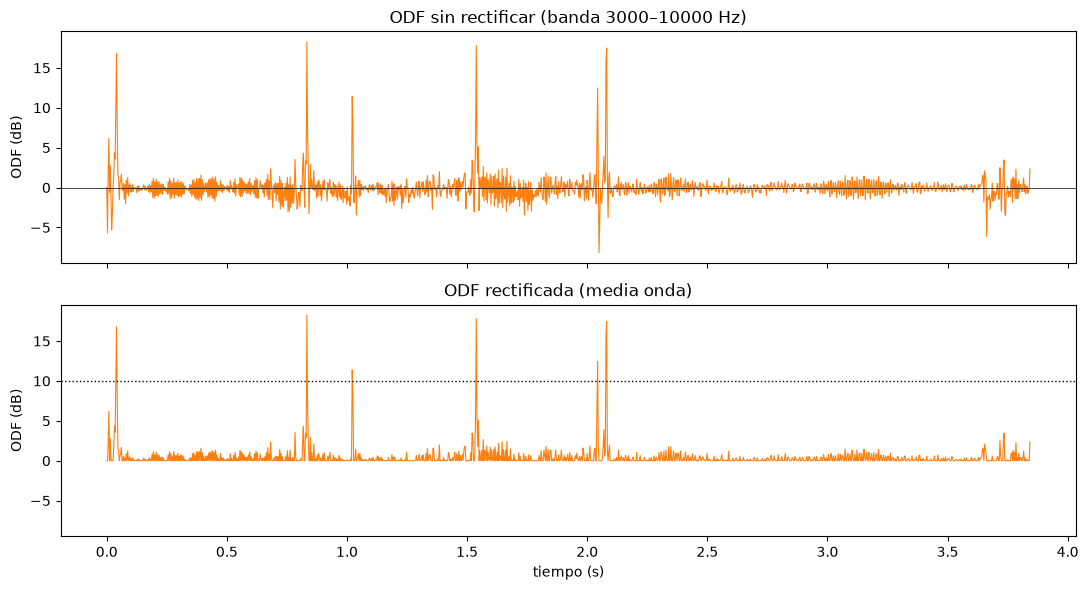

In [18]:
# ODF antes y después de la rectificación (caso 1, banda alta)
f, window, M, N, H = '../sounds/piano.wav', 'blackman', 513, 1024, 128
mX, eng_env = compute_eng_env(f, window, M, N, H)
t = np.arange(mX.shape[0]) * H / 44100

odf_raw = np.zeros_like(eng_env)
odf_raw[1:] = np.diff(eng_env, axis=0)       # sin rectificar
odf_rect = np.maximum(odf_raw, 0)            # rectificada

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
axes[0].plot(t, odf_raw[:, 1], color='C1', lw=0.8)
axes[0].axhline(0, color='k', lw=0.5)
axes[0].set_title('ODF sin rectificar (banda 3000–10000 Hz)')
axes[1].plot(t, odf_rect[:, 1], color='C1', lw=0.8)
axes[1].axhline(10, color='k', ls=':', lw=1)
axes[1].set_title('ODF rectificada (media onda)')
for ax in axes:
    ax.set_ylabel('ODF (dB)')
axes[1].set_xlabel('tiempo (s)')
plt.tight_layout()
plt.show()
